# 01. EDA — 엔진 센서 데이터 탐색

**목표:** 센서 21개 중 엔진 열화(고장 진행)를 잘 보여주는 센서 찾기

- 실행: 셀을 클릭하고 `Shift + Enter`
- 데이터 위치: `../data/train_FD001.txt`

## Step 1. 데이터 불러오기

In [8]:
import pandas as pd

# 원본 파일에는 컬럼 이름이 없어서 직접 붙여준다
cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]

df = pd.read_csv("../data/train_FD001.txt", sep=r"\s+", header=None, names=cols)
df.head()

,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## Step 2. 기본 정보 확인

In [9]:
print("크기 (행, 열):", df.shape)          # (20631, 26)이 나오면 성공
print("엔진 수:", df["unit"].nunique())
print("빈칸 개수:", df.isnull().sum().sum())

크기 (행, 열): (20631, 26)
엔진 수: 100
빈칸 개수: 0


In [10]:
# 엔진별 수명(마지막 사이클) 통계
df.groupby("unit")["cycle"].max().describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

## Step 3. RUL(남은 수명) 계산

`RUL = 그 엔진의 마지막 사이클 - 현재 사이클`

In [11]:
max_cycle = df.groupby("unit")["cycle"].transform("max")
df["RUL"] = max_cycle - df["cycle"]
df[["unit", "cycle", "RUL"]].head()

,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


## Step 4. 값이 거의 안 변하는 센서 찾기

표준편차(std)가 0에 가까우면 → 값이 거의 안 변함 → 정보가 없음

In [12]:
sensor_cols = [f"s{i}" for i in range(1, 22)]
df[sensor_cols].std().sort_values()

s1     0.000000e+00
s10    0.000000e+00
s19    0.000000e+00
s18    0.000000e+00
s16    3.469531e-18
s5     5.329200e-15
s6     1.388985e-03
s15    3.750504e-02
s8     7.098548e-02
s13    7.191892e-02
s21    1.082509e-01
s20    1.807464e-01
s11    2.670874e-01
s2     5.000533e-01
s12    7.375534e-01
s7     8.850923e-01
s17    1.548763e+00
s3     6.131150e+00
s4     9.000605e+00
s14    1.907618e+01
s9     2.208288e+01
dtype: float64

## Step 5. 그래프로 확인

- 왼쪽 = 새 엔진, 오른쪽 = 고장 직전 (RUL 0)
- 오른쪽으로 갈수록 올라가거나 내려가면 → 좋은 센서

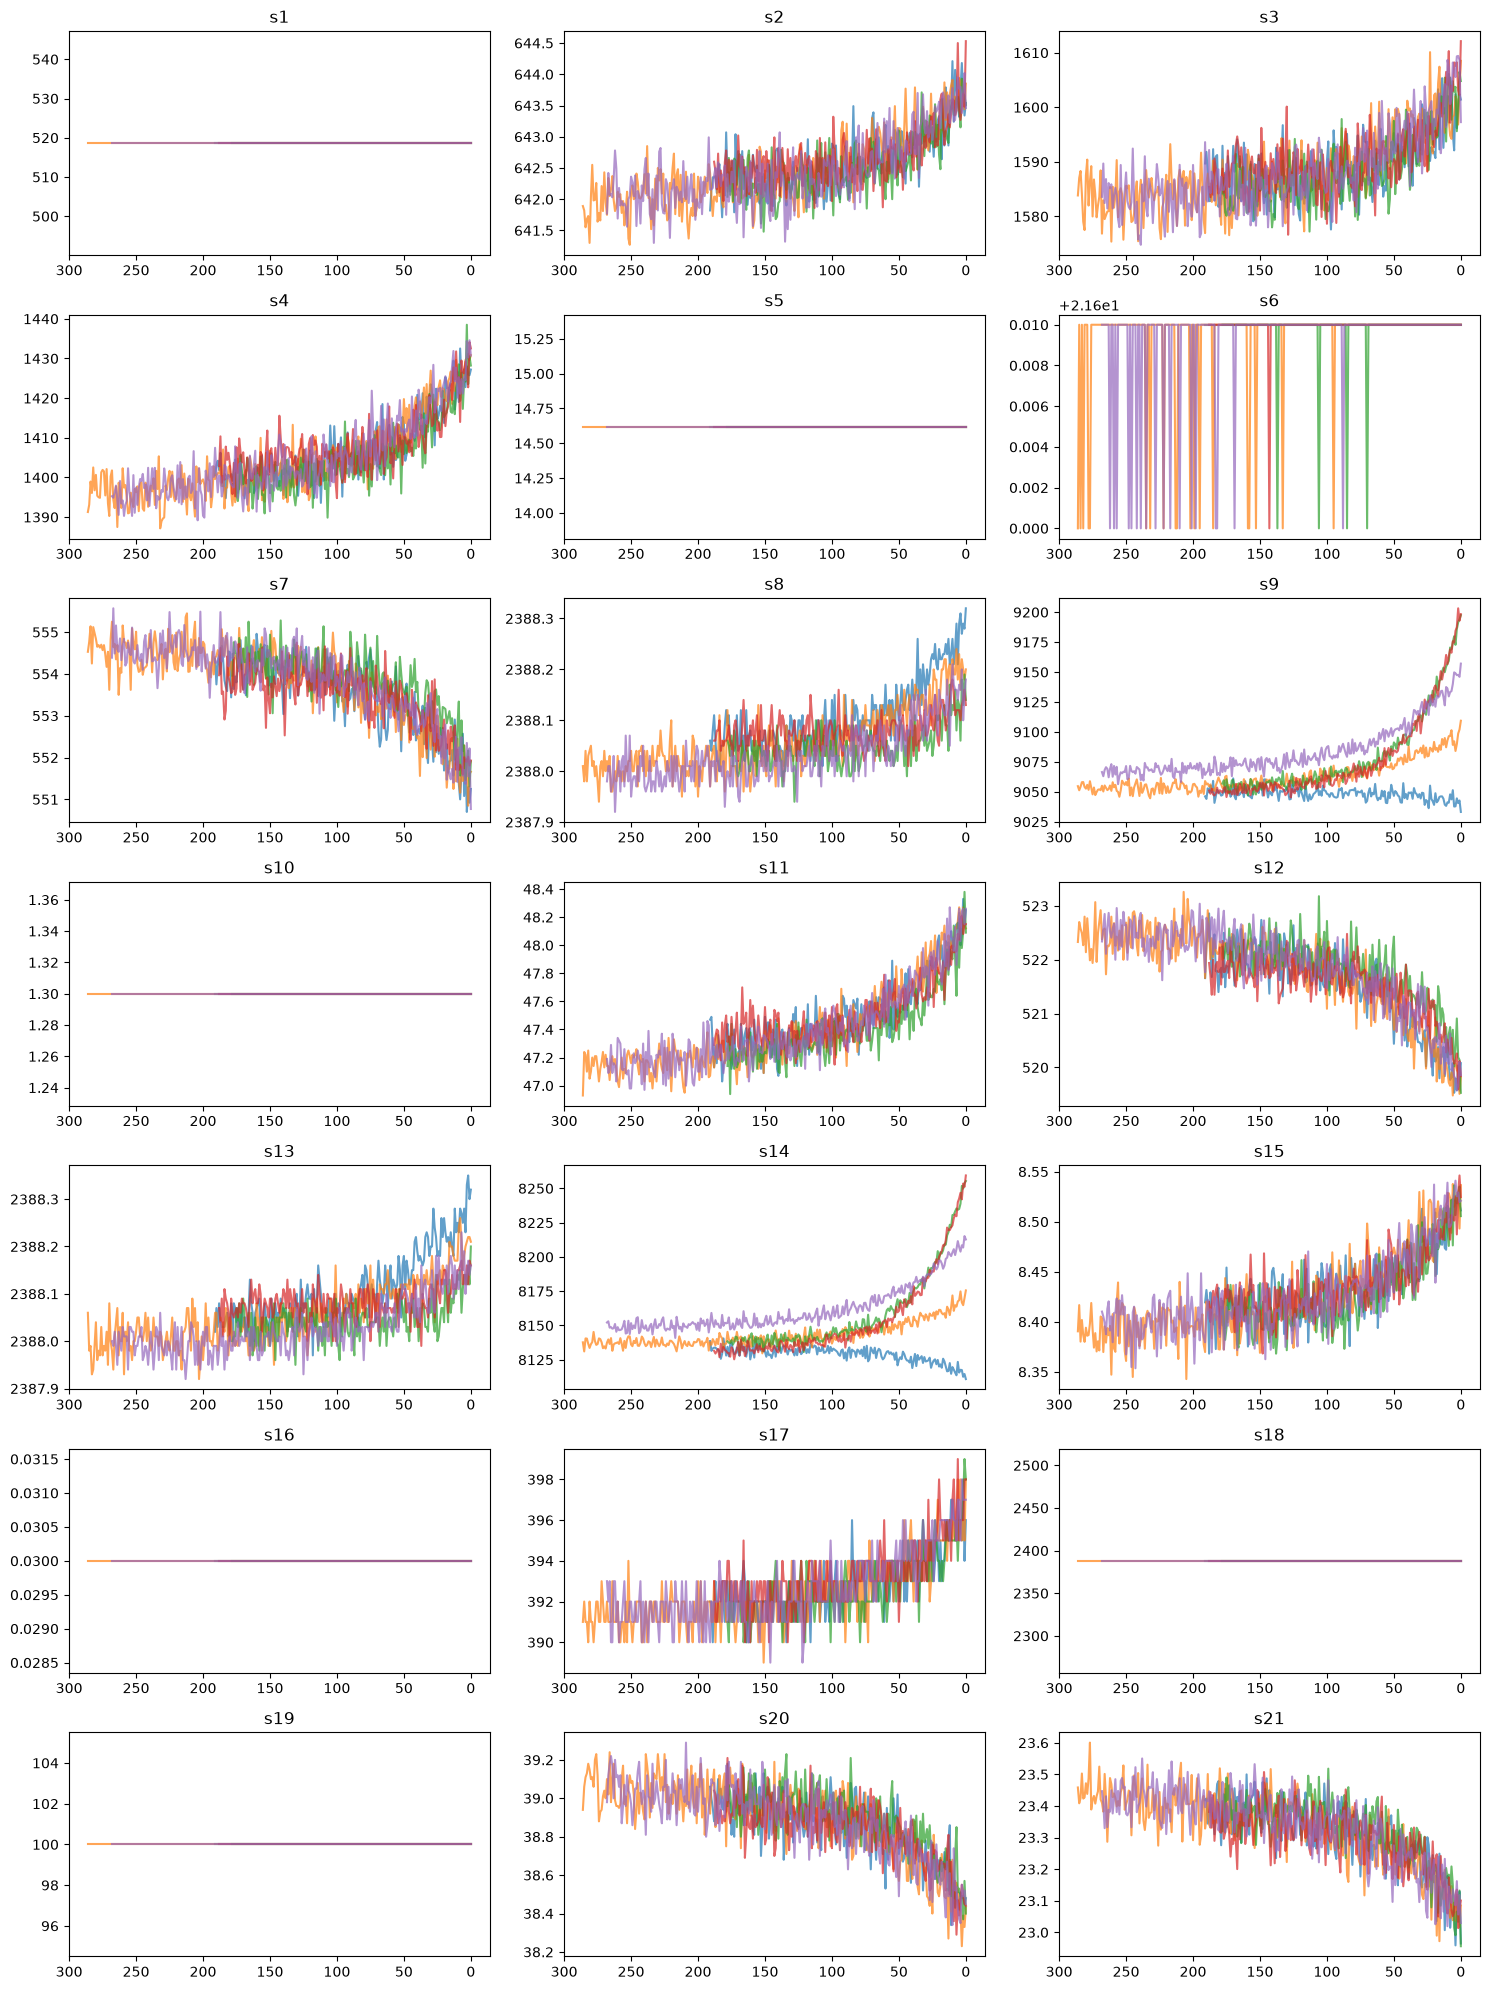

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(7, 3, figsize=(15, 20))
for ax, s in zip(axes.flat, sensor_cols):
    for unit in [1, 2, 3, 4, 5]:          # 엔진 5대만 그리기
        d = df[df["unit"] == unit]
        ax.plot(d["RUL"], d[s], alpha=0.7)
    ax.set_title(s)
    ax.invert_xaxis()
plt.tight_layout()
plt.show()

## Step 6. RUL과의 상관관계

In [14]:
corr = df[sensor_cols + ["RUL"]].corr()["RUL"].drop("RUL")
corr.abs().sort_values(ascending=False)

s11    0.696228
s4     0.678948
s12    0.671983
s7     0.657223
s15    0.642667
s21    0.635662
s20    0.629428
s2     0.606484
s17    0.606154
s3     0.584520
s8     0.563968
s13    0.562569
s9     0.390102
s14    0.306769
s6     0.128348
s1          NaN
s5          NaN
s10         NaN
s16         NaN
s18         NaN
s19         NaN
Name: RUL, dtype: float64

## ✅ 정리 (직접 채우기)

| 구분 | 센서 |
|---|---|
| ✅ 사용할 센서 | |
| ❌ 버릴 센서 | |

**발견한 점 메모:**
- 